# Uji Coba v4.2: Agen RL Tiga Aksi (pakai hasil, tanya lagi, atau ke konselor)

Tim Nusantara DSAI :

> Mahasiswa menjawab 7 butir awal. Komputer memilih satu dari tiga aksi: **BERHENTI** (pakai hasil dari jawaban yang ada), **TANYA** (minta satu butir tambahan), atau **ALIHKAN** (minta konselor meninjau).

Agen memakai **Q-learning tabel biasa, tanpa deep learning**.Imbalan memuat **penalti alarm palsu** supaya agen tidak "mengejar poin" dengan berhenti begitu skor melewati batas berat (masalah yang muncul di uji coba Desain 2).

**Cara menjalankan di Colab:** Runtime, lalu Run all (sekitar 2 sampai 4 menit; sel 0b menambah beberapa detik bila data mentah harus diunduh). Notebook mengunduh data mentah dari Open Source Psychometrics Project, membersihkannya, dan tidak memerlukan Google Drive.

Semua angka adalah **uji kelayakan**, bukan hasil final. Pembagian data uji menggunakan seed 42.

In [1]:
# =====================================================================
# LANGKAH 0. PERSIAPAN: pustaka, folder, dan data bersih
# =====================================================================
import os           # Mengatur alamat folder dan memeriksa keberadaan berkas
import zipfile      # Membuka berkas ZIP
import urllib.request # Mengunduh data dari internet
import numpy as np  # Membantu perhitungan angka
import pandas as pd # Membaca dan mengolah tabel data
import matplotlib.pyplot as plt # Membuat grafik
from sklearn.model_selection import train_test_split # Membagi data untuk latihan, validasi, dan pengujian
from sklearn.linear_model import LogisticRegression  # Membuat model prediksi kategori
from sklearn.isotonic import IsotonicRegression      # Membantu mengkalibrasi peluang prediksi model

plt.rcParams['figure.dpi'] = 72
import sys, sklearn
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)  # versi pustaka dicatat agar hasil dapat direproduksi
FOLDER = '/content/data' if os.path.exists('/content') else 'data'  # folder kerja; tidak memakai Google Drive
os.makedirs(FOLDER, exist_ok=True)
HASIL = os.path.join(FOLDER, 'hasil_ujicoba_v4_agen3aksi'); os.makedirs(HASIL, exist_ok=True) #Siapkan folder bernama hasil_ujicoba_v4_agen3aksi. Jika foldernya sudah ada, gunakan folder tersebut.
SEED_UJI = 42
f_bersih = os.path.join(FOLDER, 'dass_bersih_tahap0.csv')
if os.path.exists(f_bersih):
    d = pd.read_csv(f_bersih) #Jika berkas data bersih ada, baca isinya dan simpan sebagai tabel d
else:
    zpath = os.path.join(FOLDER, 'DASS_data_21.02.19.zip')
    if not os.path.exists(zpath):
        urllib.request.urlretrieve('https://openpsychometrics.org/_rawdata/DASS_data_21.02.19.zip', zpath)
    with zipfile.ZipFile(zpath) as z:
        nama = [n for n in z.namelist() if n.endswith('data.csv')][0]
        raw = pd.read_csv(z.open(nama), sep='\t')
    d = raw[raw[['VCL6', 'VCL9', 'VCL12']].sum(axis=1) == 0]
    d = d[(d['age'] >= 18) & (d['age'] <= 100)].drop_duplicates().copy()
    d['gender_lbl'] = d['gender'].map({1: 'Laki-laki', 2: 'Perempuan', 3: 'Lainnya', 0: 'Tidak menjawab'})
    d['kel_usia'] = pd.cut(d['age'], [17, 24, 34, 200], labels=['18-24', '25-34', '35+']).astype(str) # mengelompokkan usia menjadi “18–24”, “25–34”, dan “35+
d['kel_usia'] = d['kel_usia'].astype(str)
d = d.reset_index(drop=True)
print('Ukuran data:', d.shape)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
Ukuran data: (28474, 174)


## Langkah 0b. Bukti pembersihan data (Bagaimana data awal sebanyak 39.775 baris bisa menjadi 28.474 baris? Berapa baris yang dikeluarkan pada setiap tahap?)

Langkah 0b menyediakan tabel yang menunjukkan:

*   Jumlah data sebelum dibersihkan.
*   Jumlah data yang dikeluarkan oleh setiap aturan.
*   Jumlah data yang tersisa setelah setiap aturan.
*   Kesesuaian hasil hitungan dengan angka yang dicantumkan dalam panduan dan jumlah baris pada d.







Kesesuaian hasil hitungan dengan angka yang dicantumkan dalam panduan dan jumlah baris pada d.
Bagian ini hanya memeriksa ulang proses pembersihan data. Data awal disaring secara bertahap: pertama, mengeluarkan responden yang menandai kata rekaan (fiktif); kedua, mempertahankan responden berusia 18–100 tahun; dan ketiga, menghapus salinan baris yang seluruh isinya sama. Hasil pemeriksaan ditampilkan untuk menjelaskan perubahan dari 39.775 menjadi 28.474 baris. Bagian ini tidak mengubah data utama yang sudah dibaca. Jika data mentah tidak tersedia dan tidak bisa diunduh, pemeriksaan ini dilewati. Proses berikutnya tetap dapat berjalan selama data bersih sudah berhasil dibaca pada langkah sebelumnya.

Bagian ini hanya memeriksa ulang proses pembersihan data publik DASS dari OpenPsychometrics. Sumber dataset mencantumkan 39.775 respons sebelum penyaringan ( [openpsychometrics](https://openpsychometrics.org/_rawdata/))

Pemeriksaan dilakukan secara berurutan. Pertama, notebook mengeluarkan responden yang mencentang salah satu kata rekaan pada kolom VCL6 (cuivocal), VCL9 (florted), atau VCL12 (verdid). Kata rekaan digunakan sebagai pemeriksaan kualitas jawaban; hasil pemeriksaan ini tidak berarti bahwa setiap responden yang dikeluarkan pasti tidak jujur. Kedua, notebook mempertahankan responden berusia 18–100 tahun, sesuai batas usia yang diterapkan dalam analisis ini. Ketiga, notebook menghapus salinan baris yang seluruh isi kolomnya sama persis. Hasil pemeriksaan pada notebook menunjukkan perubahan dari 39.775 menjadi 28.474 baris.


Bagian pemeriksaan ini tidak mengganti atau mengubah data utama yang sudah dibaca pada langkah sebelumnya. Jika berkas data mentah tidak tersedia dan tidak bisa diunduh, pemeriksaan ulang dilewati dan notebook menampilkan pemberitahuan. Langkah berikutnya tetap dapat berjalan selama data bersih sudah berhasil dibaca pada langkah sebelumnya [item respon warehouse](https://itemresponsewarehouse.org/itemtext_issues.html).

Penyaringan tersebut belum membatasi responden berdasarkan status mahasiswa atau kewarganegaraan Indonesia.


In [2]:
# =====================================================================
# LANGKAH 0b. BUKTI PEMBERSIHAN DATA (Bagian ini hanya memeriksa proses pembersihan dan tidak mengubah tabel data utama (d) yang digunakan pada langkah berikutnya)
# =====================================================================
import io
RAW_ZIP = os.path.join(FOLDER, 'DASS_data_21.02.19.zip')
ANGKA_PANDUAN = {'mentah': 39775, 'kata fiktif': 5192, 'usia': 6109, 'ganda': 0, 'bersih': 28474} #memeriksa apakah perhitungan ulang menghasilkan angka yang sama
def ambil_mentah():
    if not os.path.exists(RAW_ZIP):
        with urllib.request.urlopen('https://openpsychometrics.org/_rawdata/DASS_data_21.02.19.zip', timeout=60) as r:
            data = r.read()
        try:
            open(RAW_ZIP, 'wb').write(data)
        except Exception:
            return pd.read_csv(io.BytesIO(zipfile.ZipFile(io.BytesIO(data)).read([n for n in zipfile.ZipFile(io.BytesIO(data)).namelist() if n.endswith('data.csv')][0])), sep='\t')
    with zipfile.ZipFile(RAW_ZIP) as z:
        nama = [n for n in z.namelist() if n.endswith('data.csv')][0]
        return pd.read_csv(z.open(nama), sep='\t')
def hitung_pembersihan(raw, urutan='fiktif_dulu'): #Ambil tabel data mentah, lakukan penyaringan sesuai urutan yang dipilih, dan catat jumlah baris pada setiap tahap.
    fiktif_ok = lambda x: x[x[['VCL6', 'VCL9', 'VCL12']].sum(axis=1) == 0] #menjumlahkan nilai ketiga kolom tersebut untuk setiap responden, lalu hanya mempertahankan baris yang jumlahnya nol
   # =====================================================================
   # Awalnya ada 39.775 baris.
   # Sebanyak 5.192 baris dikeluarkan.
   # Tersisa 34.583 baris
   # =====================================================================
    usia_ok = lambda x: x[(x['age'] >= 18) & (x['age'] <= 100)] # hanya responden berusia 18 sampai 100 tahun yang dipertahankan, termasuk tepat 18 dan tepat 100 tahun
   # =====================================================================
   # Awalnya ada 34.583 baris.
   # Sebanyak 6.109 baris dikeluarkan.
   # Tersisa 28.474 baris
   # =====================================================================
    langkah = [('Data mentah', raw)]
    a = fiktif_ok(raw) if urutan == 'fiktif_dulu' else usia_ok(raw)
    b = usia_ok(a) if urutan == 'fiktif_dulu' else fiktif_ok(a)
    c = b.drop_duplicates() #menghapus salinan baris yang seluruh isi kolomnya sama persis, dengan mempertahankan satu salinan
    nama = ['1. Kata fiktif', '2. Batas usia'] if urutan == 'fiktif_dulu' else ['1. Batas usia', '2. Kata fiktif']
    baris, sebelum = [('Data mentah', len(raw), 0, len(raw))], len(raw)
    for n_, x in zip(nama + ['3. Baris ganda'], [a, b, c]):
        baris.append((n_, sebelum, sebelum - len(x), len(x))); sebelum = len(x)
    return pd.DataFrame(baris, columns=['Langkah', 'Sebelum', 'Dibuang', 'Sisa'])
try:
    mentah = ambil_mentah()
    t_urut = hitung_pembersihan(mentah)
    display(t_urut)
    t_urut.to_csv(os.path.join(HASIL, 'tabel_pembersihan_data.csv'), index=False) #penyimpanan hasil pembersihan
    dibuang = dict(zip(['fiktif', 'usia', 'ganda'], t_urut['Dibuang'][1:]))
    cocok = (len(mentah) == ANGKA_PANDUAN['mentah'] and dibuang['fiktif'] == ANGKA_PANDUAN['kata fiktif']
             and dibuang['usia'] == ANGKA_PANDUAN['usia'] and dibuang['ganda'] == ANGKA_PANDUAN['ganda']
             and int(t_urut['Sisa'].iloc[-1]) == ANGKA_PANDUAN['bersih'] == len(d))
    print('COCOK dengan angka panduan dan dengan data bersih yang dipakai.' if cocok else #semua perbandingan jumlah tersebut terpenuhi.
          'BERBEDA dari angka panduan (mentah 39.775; fiktif 5.192; usia 6.109; ganda 0; bersih 28.474) atau dari data bersih yang dipakai (%d baris). Laporkan ke grup.' % len(d)) #Dari 34.583 baris yang masuk tahap pemeriksaan usia, 6.109 baris dikeluarkan sehingga tersisa 28.474 baris.
    t_balik = hitung_pembersihan(mentah, 'usia_dulu') #usia diperiksa lebih dahulu, baru kata fiktif
    print('Cek urutan: bila usia diperiksa lebih dulu, yang dibuang adalah', t_balik['Dibuang'].tolist()[1:], '(urutan aturan memengaruhi jumlah per aturan, bukan hasil akhir bila aturan saling lepas).')
except Exception as e:
    print('Data mentah tidak bisa diambil (%s). Langkah ini dilewati; notebook memakai berkas bersih yang sudah ada.' % type(e).__name__)

,Langkah,Sebelum,Dibuang,Sisa
0,Data mentah,39775,0,39775
1,1. Kata fiktif,39775,5192,34583
2,2. Batas usia,34583,6109,28474
3,3. Baris ganda,28474,0,28474


COCOK dengan angka panduan dan dengan data bersih yang dipakai.
Cek urutan: bila usia diperiksa lebih dulu, yang dibuang adalah [7276, 4025, 0] (urutan aturan memengaruhi jumlah per aturan, bukan hasil akhir bila aturan saling lepas).


In [3]:
display(d.head())

,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,hand,religion,orientation,race,voted,married,familysize,major,gender_lbl,kel_usia
0,2,36,3215,2,13,7731,3,5,4156,4,...,3,10,1,10,2,1,4,Psychology,Perempuan,18-24
1,1,18,6116,1,28,3193,2,2,12542,1,...,1,4,1,70,2,1,4,NaN,Perempuan,18-24
2,3,38,5187,2,28,2600,4,9,2015,1,...,1,2,2,60,2,1,3,computer programming,Perempuan,18-24
3,3,37,4024,3,35,2116,2,18,3408,2,...,1,6,1,60,2,1,2,NaN,Perempuan,18-24
4,1,35,3055,1,24,1812,1,30,3266,1,...,1,1,1,60,2,1,2,Sociology,Perempuan,18-24


melihat isi d (62 kolom) secara langsung di Colab

In [4]:
print(d.columns.tolist())

['Q1A', 'Q1I', 'Q1E', 'Q2A', 'Q2I', 'Q2E', 'Q3A', 'Q3I', 'Q3E', 'Q4A', 'Q4I', 'Q4E', 'Q5A', 'Q5I', 'Q5E', 'Q6A', 'Q6I', 'Q6E', 'Q7A', 'Q7I', 'Q7E', 'Q8A', 'Q8I', 'Q8E', 'Q9A', 'Q9I', 'Q9E', 'Q10A', 'Q10I', 'Q10E', 'Q11A', 'Q11I', 'Q11E', 'Q12A', 'Q12I', 'Q12E', 'Q13A', 'Q13I', 'Q13E', 'Q14A', 'Q14I', 'Q14E', 'Q15A', 'Q15I', 'Q15E', 'Q16A', 'Q16I', 'Q16E', 'Q17A', 'Q17I', 'Q17E', 'Q18A', 'Q18I', 'Q18E', 'Q19A', 'Q19I', 'Q19E', 'Q20A', 'Q20I', 'Q20E', 'Q21A', 'Q21I', 'Q21E', 'Q22A', 'Q22I', 'Q22E', 'Q23A', 'Q23I', 'Q23E', 'Q24A', 'Q24I', 'Q24E', 'Q25A', 'Q25I', 'Q25E', 'Q26A', 'Q26I', 'Q26E', 'Q27A', 'Q27I', 'Q27E', 'Q28A', 'Q28I', 'Q28E', 'Q29A', 'Q29I', 'Q29E', 'Q30A', 'Q30I', 'Q30E', 'Q31A', 'Q31I', 'Q31E', 'Q32A', 'Q32I', 'Q32E', 'Q33A', 'Q33I', 'Q33E', 'Q34A', 'Q34I', 'Q34E', 'Q35A', 'Q35I', 'Q35E', 'Q36A', 'Q36I', 'Q36E', 'Q37A', 'Q37I', 'Q37E', 'Q38A', 'Q38I', 'Q38E', 'Q39A', 'Q39I', 'Q39E', 'Q40A', 'Q40I', 'Q40E', 'Q41A', 'Q41I', 'Q41E', 'Q42A', 'Q42I', 'Q42E', 'country', 'source

melihat seluruh nama kolom

| Urutan pemeriksaan | Dikeluarkan pada tahap pertama | Dikeluarkan pada tahap kedua |
| ------------------ | ------------------------------ | ---------------------------- |
| Kata fiktif → usia | 5.192 karena kata fiktif       | 6.109 karena usia            |
| Usia → kata fiktif | 7.276 karena usia              | 4.025 karena kata fiktif     |

Mengapa jumlah per tahap berubah? Karena seorang responden bisa melanggar dua aturan sekaligus.

Urutannya dibalik hanya untuk menunjukkan bahwa satu responden bisa melanggar dua aturan sekaligus, misalnya usianya 16 tahun dan mencentang kata fiktif. Jika usia diperiksa dahulu, ia tercatat dibuang karena usia; jika kata fiktif diperiksa dahulu, ia tercatat dibuang karena kata fiktif. Setelah dibuang, ia tidak diperiksa lagi pada tahap berikutnya. Jadi, jumlah yang tercatat dibuang pada masing-masing tahap bisa berbeda, tetapi orang yang akhirnya dipertahankan tetap sama. Ini hanya pemeriksaan tambahan, bukan perubahan aturan pembersihan.

## Langkah 1. Acuan, 7 butir awal, dan butir tambahan

* **Acuan** ("jawaban benar" yang hanya dipegang simulator): pita depresi dari 14 butir DASS-42 (normal, ringan, sedang, berat, sangat berat).
* **Yang dilihat komputer di awal**: 7 butir depresi DASS-21.
* **Butir tambahan**: 7 butir depresi DASS-42 lainnya disembunyikan. Komputer boleh membuka paling banyak 3, dalam urutan tetap (butir yang paling banyak menambah informasi, dihitung dari data latih).

In [5]:
# =====================================================================
# LANGKAH 1. ACUAN, FITUR, PEMBAGIAN DATA
# =====================================================================
BUTIR14 = [3, 5, 10, 13, 16, 17, 21, 24, 26, 31, 34, 37, 38, 42]   # 14 butir depresi DASS-42 untuk menentukan kategori pembanding
BUTIR7 = [3, 42, 10, 26, 31, 17, 38]                                  # 7 butir depresi DASS-21 (nomor DASS-42) yang boleh dilihat diawal, sebagai bahan prediksi awal
SEMBUNYI = [b for b in BUTIR14 if b not in BUTIR7]  # 7 butir depresi DASS-42 yang TIDAK ada di DASS-21: 5, 13, 16, 21, 24, 34, 37. Jawabannya sebenarnya sudah tersedia dalam tabel d, tetapi sengaja tidak diperlihatkan kepada sistem pada awal simulasi.
NAMA_PITA = ['Normal', 'Ringan', 'Sedang', 'Berat', 'Sangat berat']
skor14 = (d[['Q%dA' % b for b in BUTIR14]] - 1).sum(axis=1).values

   # =====================================================================
   # Ambil jawaban setiap responden pada 14 butir tersebut.
   # Kurangi setiap nilai jawaban dengan 1.
   # Jumlahkan hasilnya untuk masing-masing responden.
   # Pengurangan 1 mengubah nilai jawaban yang semula 1–4 menjadi 0–3 sebelum dijumlahkan.
   # =====================================================================

y_all = np.digitize(skor14, [10, 14, 21, 28])  # pita acuan 0-4
X7 = (d[['Q%dA' % b for b in BUTIR7]] - 1).values # Tujuh jawaban awal (nilai 0-3) disimpan dalam X7: satu baris per responden, 7 kolom
Xh = (d[['Q%dA' % b for b in SEMBUNYI]] - 1).values # Tujuh jawaban butir tersembunyi (nilai 0-3); hanya dibuka bila agen memilih TANYA
idx_all = np.arange(len(d))
sisa, uji = train_test_split(idx_all, test_size=0.20, stratify=y_all, random_state=SEED_UJI) # 20% dari seluruh data dialokasikan sebagai data uji akhir (20%×28.474=5.694,8), Sisa untuk pengembangan: 22.779 responden (80%)
latih, val = train_test_split(sisa, test_size=0.25, stratify=y_all[sisa], random_state=SEED_UJI) #  seperempat dari sisa 80% menghasilkan sekitar 20% dari keseluruhan data 25%×80%=20% (5.695)
val_iso, val_conf = train_test_split(val, test_size=0.50, stratify=y_all[val], random_state=SEED_UJI)
latih_agen = np.concatenate([val_iso, val_conf])            # data latih agen = data validasi (bukan data uji)
# Urutan butir tambahan: korelasi terbesar dengan "sisa" skor (skor 14 butir dikurangi 2 x skor 7 butir) di data latih
sisa_skor = skor14[latih] - 2 * X7[latih].sum(1) # skor 14 butir dikurangi 2 x skor 7 butir: bagian skor yang belum tertangkap oleh 7 butir awal
kor = [np.corrcoef(Xh[latih, j], sisa_skor)[0, 1] for j in range(len(SEMBUNYI))] #Korelasi Pearson mengukur hubungan linear antara dua kumpulan angka dan bernilai antara −1 sampai 1. Nilai positif yang lebih besar menunjukkan hubungan searah yang lebih kuat: ketika satu nilai naik, nilai lainnya cenderung ikut naik. Dihitung pada data latih model (latih), bukan pada data uji.
URUT = list(np.argsort(kor)[::-1]); KMAX = 3 #Susun posisi butir dari nilai korelasi paling besar sampai paling kecil.Sistem hanya boleh membuka maksimal tiga pertanyaan tambahan.
print('Butir tambahan yang boleh dibuka (nomor DASS-42, sesuai urutan):', [SEMBUNYI[j] for j in URUT[:KMAX]]) #nomor butir DASS-42 yang bisa dibaca, maksimal 3 pertanyaan.
print('Latih model %d | latih agen %d | uji %d | kasus berat ke atas di uji %d' % (len(latih), len(latih_agen), len(uji), (y_all[uji] >= 3).sum()))
usia = d['kel_usia'].values
gender = d['gender_lbl'].values

Butir tambahan yang boleh dibuka (nomor DASS-42, sesuai urutan): [16, 24, 5]
Latih model 17084 | latih agen 5695 | uji 5695 | kasus berat ke atas di uji 2694


Acuan tidak langsung diberikan kepada agen sebagai informasi untuk mengambil keputusan. Agen nantinya memakai ringkasan keluaran model prediksi, sedangkan acuan digunakan dalam proses penilaian dan pemberian imbalan saat latihan

Membagi data dengan seed 42
Setelah acuan dan jawaban disiapkan, notebook membagi data menjadi:
| Bagian data                                              | Jumlah responden | Kegunaan                                                             |
| -------------------------------------------------------- | ---------------- | -------------------------------------------------------------------- |
| Data latih model                                         | 17.084           | Melatih model prediksi                                               |
| Data validasi, yang juga dipakai sebagai data latih agen | 5.695            | Kalibrasi model, pelatihan agen, dan pemilihan kebijakan sesuai kode |
| Data uji                                                 | 5.695            | Menguji kebijakan setelah dipilih                                    |

Data validasi juga dibagi lagi menjadi dua bagian bernama val_iso dan val_conf; keduanya kemudian digabungkan sebagai latih_agen. Pembagian data menggunakan seed 42 dan mempertimbangkan kategori acuan agar komposisi kategori dijaga dalam pembagian.

skor dibagi menjadi lima kategori (pita acuan):
| Skor total 14 butir | Kategori acuan | Kode kategori |
| ------------------- | -------------- | ------------- |
| 0–9                 | Normal         | 0             |
| 10–13               | Ringan         | 1             |
| 14–20               | Sedang         | 2             |
| 21–27               | Berat          | 3             |
| 28–42               | Sangat berat   | 4             |

dasar ilmiah proses pembelajaran (membedakan proses belajar dan pemilihan model dari penilaian akhir) dibedakan atas :
1.   Data latih menjadi bahan belajar model prediksi.
2.   Data validasi/pengembangan digunakan untuk mengembangkan sistem dan memilih kebijakan. Pada notebook ini, bagian tersebut juga digunakan untuk melatih agen.
3.   Data uji menjadi bahan ujian akhir setelah kebijakan dipilih.

[Guyon dan Elisseeff](https://www.jmlr.org/papers/volume3/guyon03a/guyon03a.pdf) menjelaskan bahwa evaluasi akhir memerlukan data uji independen, sementara data selain data uji dapat digunakan untuk pelatihan dan pemilihan model melalui pembagian validasi atau validasi silang.

Angka pembagian berasal dari rancangan sekitar 60% data latih model, 20% data pengembangan, dan 20% data uji. Pembagian dilakukan secara acak terstratifikasi berdasarkan lima kategori acuan, dengan seed 42 agar dapat direproduksi. Prinsip pemisahan pengembangan dan pengujian didukung literatur, tetapi rasio 60:20:20 merupakan pilihan rancangan pada eksperimen ini, bukan ketentuan wajib dari satu jurnal.

| Pengaturan      | Fungsi                                                                              |
| --------------- | ----------------------------------------------------------------------------------- |
| test_size       | Menentukan besarnya bagian data                                                     |
| stratify        | Menjaga agar proporsi kategori acuan kurang lebih terwakili pada bagian-bagian data |
| random_state=42 | Membuat hasil pengacakan pembagian dapat diulang                                    |


| Bagian                  | Yang dihitung                                                            |
| ----------------------- | ------------------------------------------------------------------------ |
| len(latih)              | Jumlah responden untuk melatih model prediksi                            |
| len(latih_agen)         | Jumlah responden untuk melatih agen                                      |
| len(uji)                | Jumlah responden dalam data uji                                          |
| (y_all[uji] >= 3).sum() | Jumlah responden data uji yang kategori acuannya berat atau sangat berat |                              

menggunakan >= 3, karena kode kategorinya adalah 0 = normal, 1 = ringan, 2 = sedang, 3 = berat, dan 4 = sangat berat.

 Latih model 17084 | latih agen 5695 | uji 5695 |
kasus berat ke atas di uji 2694

 2.694 adalah bagian dari 5.695 responden data uji, bukan kelompok data tambahan. Mereka memiliki kategori acuan berat atau sangat berat.                                                                



sisa_skor = skor14[latih] - 2 * X7[latih].sum(1)
kor = [np.corrcoef(Xh[latih, j], sisa_skor)[0, 1] for j in range(len(SEMBUNYI))]
URUT = list(np.argsort(kor)[::-1]); KMAX = 3
print('Butir tambahan yang boleh dibuka (nomor DASS-42, sesuai urutan):', [SEMBUNYI[j] for j in URUT[:KMAX]])
print('Latih model %d | latih agen %d | uji %d | kasus berat ke atas di uji %d' % (len(latih), len(latih_agen), len(uji), (y_all[uji] >= 3).sum()))
usia = d['kel_usia'].values
gender = d['gender_lbl'].values


Hitung selisih skor pada data latih → hitung korelasi setiap butir tersembunyi dengan selisih itu → urutkan butir → izinkan maksimal tiga tambahan → tampilkan jumlah data → siapkan label kelompok untuk evaluasi.

## Langkah 2. Melatih model prediksi untuk 7, 8, 9, dan 10 butir

Pada langkah ini, notebook melatih empat model regresi logistik untuk memperkirakan kategori depresi: normal, ringan, sedang, berat, atau sangat berat. Setiap model menggunakan jumlah jawaban yang berbeda, sesuai banyaknya butir yang sudah dibuka.
| Model          | Jawaban yang digunakan                           |
| -------------- | ------------------------------------------------ |
| Model 7 butir  | Tujuh jawaban awal                               |
| Model 8 butir  | Tujuh jawaban awal + jawaban butir 16            |
| Model 9 butir  | Tujuh jawaban awal + jawaban butir 16 dan 24     |
| Model 10 butir | Tujuh jawaban awal + jawaban butir 16, 24, dan 5 |

Keempat model dilatih menggunakan data latih dan kategori acuan dari 14 butir depresi DASS-42. Setiap model menghasilkan peluang untuk lima kategori. Peluang tersebut kemudian disesuaikan melalui kalibrasi menggunakan bagian data validasi.

Model prediksi dan agen Q-learning memiliki tugas yang berbeda. Model prediksi memperkirakan kategori berdasarkan jawaban yang tersedia. Agen Q-learning, yang dilatih pada tahap berikutnya, memilih apakah akan BERHENTI dan memakai hasil prediksi, TANYA satu butir tambahan sesuai urutan, atau ALIHKAN ke konselor.

Tabel di akhir langkah ini hanya menilai ketepatan tebakan model. Agen Q-learning belum digunakan untuk memilih siapa yang cukup memakai hasil awal, perlu pertanyaan tambahan, atau perlu ditinjau konselor.

In [6]:
# =====================================================================
# LANGKAH 2. MODEL PREDIKSI PER JUMLAH BUTIR (menebak kategori)
# Tujuan: melatih 4 model prediksi pita (7, 8, 9, 10 butir),
# Latih: model belajar dari jawaban responden dan kategori acuan untuk menghasilkan peluang lima kategori depresi yaitu normal, ringan, sedang, berat, dan sangat berat.
# Sesuaikan: peluang dikalibrasi menggunakan data validasi, lalu dinormalkan agar total lima peluang menjadi 100%.
# Nilai: prediksi dibandingkan dengan kategori acuan pada data uji untuk menghitung akurasi dan kasus berat yang terlewat.
# =====================================================================

# (A) FUNGSI KALIBRASI: merapikan angka peluang dari model
# p_cal = peluang model pada data val_iso, y_cal = pita acuan val_iso,
# p_baru = peluang yang ingin dirapikan
def kalibrasi_isotonic(p_cal, y_cal, p_baru):
    # siapkan tabel kosong seukuran p_baru
    out = np.zeros_like(p_baru)
    # ulangi untuk tiap pita: 0=normal, 1=ringan, 2=sedang, 3=berat, 4=sangat berat
    for k in range(p_baru.shape[1]):
        # Siapkan alat kalibrasi peluang.
        # Batasi hasil antara 0 dan 1.
        # Jika masukan di luar rentang yang dipelajari,
        # gunakan hasil pada batas terdekat.
        ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
        # Pelajari penyesuaian peluang kategori k
        # dengan membandingkan peluang model dan kategori acuan.
        # Target: 1 jika responden masuk kategori k, 0 jika tidak.
        ir.fit(p_cal[:, k], (y_cal == k).astype(float));
        # Terapkan penyesuaian pada peluang kategori k,
        # lalu simpan hasilnya.
        out[:, k] = ir.predict(p_baru[:, k]) #Gunakan aturan penyesuaian yang baru dipelajari untuk mengubah peluang kategori ke-k, lalu simpan hasilnya di kolom ke-k pada tabel out
    # Setelah semua kategori selesai disesuaikan (baris ini HARUS di luar perulangan for),
    # hitung total lima hasil untuk setiap responden.
    # Total ini akan dipakai untuk menormalkan peluang.
    s = out.sum(axis=1, keepdims=True)
    # bagi dengan jumlahnya agar totalnya 1 (100%); jika semuanya 0, pakai peluang asli
    return np.where(s > 0, out / np.where(s > 0, s, 1), p_baru)

# (B) FUNGSI FITUR: jawaban yang boleh dilihat model
# gabungkan 7 jawaban awal dengan k jawaban tambahan (urutan 16, 24, 5)
# k=0 berarti 7 kolom, k=1 berarti 8, k=2 berarti 9, k=3 berarti 10
def fitur(idx, k):
    return np.hstack([X7[idx], Xh[idx][:, URUT[:k]]]).astype(float)

# (C) MELATIH 4 MODEL PENEBAK (k = 0, 1, 2, 3)
MODEL = []
for k in range(KMAX + 1):
    # latih regresi logistik dengan data latih model; sasarannya pita acuan 14 butir
    # max_iter=3000 adalah batas langkah hitung, bukan jumlah pengujian
    m = LogisticRegression(max_iter=3000).fit(fitur(latih, k), y_all[latih])
    # simpan model beserta peluangnya pada val_iso sebagai bahan kalibrasi
    MODEL.append((m, m.predict_proba(fitur(val_iso, k))))

# (D) FUNGSI PELUANG: tebakan model yang sudah dikalibrasi
def peluang(idx, k):
    # ambil model ke-k dan peluang kalibrasinya
    m, p_iso = MODEL[k]
    # tebak peluang 5 pita, lalu rapikan dengan kalibrasi
    return kalibrasi_isotonic(p_iso, y_all[val_iso], m.predict_proba(fitur(idx, k)))

# (E) PELUANG UNTUK MELATIH AGEN (PA) DAN UNTUK UJIAN (PU)
PA = {k: peluang(latih_agen, k) for k in range(KMAX + 1)}
PU = {k: peluang(uji, k) for k in range(KMAX + 1)}
# pita acuan sebagai kunci jawaban: yA untuk latih agen, yU untuk uji
yA, yU = y_all[latih_agen], y_all[uji]

# (F) TABEL HASIL MODEL PENEBAK SAJA (tanpa agen, tanpa konselor)
baris = []
for k in range(KMAX + 1):
    # tebakan = pita dengan peluang terbesar
    pb = PU[k].argmax(1)
    # akurasi = persentase tebakan yang sama persis dengan acuan
    # terlewat = acuan berat ke atas (>=3) tetapi ditebak lebih ringan (<3)
    baris.append({'Butir terlihat': 7 + k, 'Akurasi 5 pita (uji)': (pb == yU).mean(),
                  'Kasus berat terlewat bila tanpa konselor': int(((yU >= 3) & (pb < 3)).sum())})
# tampilkan tabel, dibulatkan 3 angka desimal
display(pd.DataFrame(baris).round(3))

,Butir terlihat,Akurasi 5 pita (uji),Kasus berat terlewat bila tanpa konselor
0,7,0.819,183
1,8,0.843,117
2,9,0.860,116
3,10,0.878,85


Hasil pada bagian ini menunjukkan ketepatan model dalam menebak lima kategori depresi—normal, ringan, sedang, berat, dan sangat berat—berdasarkan jumlah jawaban yang digunakan.
| Butir yang digunakan | Prediksi kategori yang tepat | Kasus berat ke atas yang terlewat |
| -------------------- | ---------------------------- | --------------------------------- |
| 7 butir              | 81,9%                        | 183 responden                     |
| 8 butir              | 84,3%                        | 117 responden                     |
| 9 butir              | 86,0%                        | 116 responden                     |
| 10 butir             | 87,8%                        | 85 responden                      |

“Kasus berat terlewat” berarti kategori acuan responden adalah berat atau sangat berat, tetapi model memprediksinya sebagai normal, ringan, atau sedang. Angka tersebut dihitung tanpa bantuan konselor.

Pada hasil ini, semakin banyak jawaban yang digunakan, prediksi semakin tepat dan kasus berat yang terlewat semakin sedikit. Namun, dengan 10 butir pun masih ada 85 kasus yang terlewat. Kolom index hanya nomor urut baris, bukan hasil penilaian.

**Catatan perbaikan (20 November 2026).** Angka di tabel ini adalah keluaran Colab 15 November dengan kode yang benar. Angka yang sempat tertulis di sini (74,8%, 78,0%, 81,2%, 84,9%) muncul karena baris `s = out.sum(...)` dan `return` pada fungsi `kalibrasi_isotonic` tergeser masuk ke dalam perulangan `for`, sehingga hanya kategori Normal yang dikalibrasi. Setelah *Run all*, pastikan keluaran Langkah 2 kembali menjadi 0,819 / 0,843 / 0,860 / 0,878 dan 183 / 117 / 116 / 85.

Langkah ini menyiapkan empat model prediksi. Setiap model bertugas memperkirakan kategori depresi berdasarkan jumlah jawaban yang tersedia.
| Nilai k | Jumlah butir | Jawaban yang digunakan           |
| ------- | ------------ | -------------------------------- |
| 0       | 7            | Tujuh jawaban awal               |
| 1       | 8            | Tujuh awal + butir 16            |
| 2       | 9            | Tujuh awal + butir 16 dan 24     |
| 3       | 10           | Tujuh awal + butir 16, 24, dan 5 |

Keempat model dilatih menggunakan jawaban responden pada data latih model dan kategori acuan dari 14 butir. Jadi, model belajar dari contoh pola jawaban yang kategori acuannya sudah diketahui.

Perintah yang diawali def baru mendefinisikan fungsi, yaitu menyiapkan sekumpulan perintah untuk dipanggil kemudian. Jadi, meskipun fungsi kalibrasi ditulis sebelum bagian pelatihan, proses kalibrasinya belum langsung dijalankan.

Urutan kerja utamanya adalah:
1.   Menyiapkan fungsi kalibrasi dan fungsi penyusun jawaban.
2.  Melatih empat model regresi logistik.
3.   Memanggil fungsi peluang() untuk menghasilkan peluang yang sudah dikalibrasi.
4.   Menyiapkan hasil untuk data latih agen dan data uji.
5.   Menghitung tabel evaluasi.


Setiap responden memperoleh lima nilai peluang dengan urutan:
Normal | Ringan | Sedang | Berat | Sangat berat

Contoh buatan:
0,05 | 0,10 | 0,50 | 0,25 | 0,10

Artinya, kategori dengan peluang terbesar adalah “Sedang”. Ketika kode menjalankan argmax(1), yang diambil adalah kode kategori dengan peluang paling besar, bukan angka peluangnya.


Dalam notebook, kode kategori adalah:
0 = Normal
1 = Ringan
2 = Sedang
3 = Berat
4 = Sangat berat






| Responden | Peluang berat dari model | Kategori acuan | Nilai target |
| --------- | ------------------------ | -------------- | ------------ |
| A         | 70%                      | Berat          | 1            |
| B         | 70%                      | Sedang         | 0            |
| C         | 70%                      | Berat          | 1            |
| D         | 70%                      | Berat          | 1            |

Dari contoh sederhana ini, tiga dari empat responden masuk kategori berat. Alat penyesuai dapat mempelajari bahwa peluang awal 70% perlu disesuaikan menjadi 75% pada pola data tersebut. Dalam kode sebenarnya, penyesuaian dipelajari dari seluruh pasangan data menggunakan regresi isotonik

fit mempelajari penyesuaian, predict menerapkan penyesuaian, dan sum menghitung total lima hasil untuk setiap responden.

## Langkah 3. Lingkungan simulasi dan agen

| Unsur RL | Di penelitian kita |
|---|---|
| Agen | Petugas pemilah di sistem skrining |
| Lingkungan | Simulator: memegang 14 jawaban, hanya membuka yang diminta |
| Keadaan | Jumlah butir tambahan yang sudah dibuka (0-3) x pita tebakan (5) x kelompok peluang berat (5) = 100 keadaan |
| Aksi | 0 = BERHENTI (pakai hasil), 1 = TANYA satu butir lagi, 2 = ALIHKAN ke konselor |
| Imbalan | TANYA: **-0,1** per butir. ALIHKAN: **-λ** (biaya waktu konselor; λ diatur agar konselor meninjau sekitar 10%). BERHENTI: **-10** bila kasus berat terlewat, **-selisih pita - 2** bila alarm palsu (bukan berat ditandai berat), **-selisih pita** untuk salah pita lainnya, 0 bila tepat |
| Episode | Satu peserta: beberapa langkah TANYA, lalu BERHENTI atau ALIHKAN (gamma = 1) |

Penalti alarm palsu adalah jawaban atas kekhawatiran Mas Romi: tanpa penalti ini, agen belajar berhenti begitu skor melewati batas berat sehingga banyak orang ditandai berat padahal tidak. Laju belajar menurun (alpha = 1 / kunjungan^0,6) dipakai agar hasil stabil dan tidak bergantung keberuntungan.

In [7]:
# =====================================================================
# LANGKAH 3. KEADAAN, IMBALAN, Q-LEARNING TABEL
# Tujuan: menyiapkan "dunia" tempat agen belajar (lingkungan simulasi), aturan nilai
# (imbalan), cara agen belajar (Q-learning), cara agen dijalankan setelah selesai belajar,
# dan cara menilai hasilnya.
# Sel ini hanya MENDEFINISIKAN fungsi (def). Latihan baru berjalan di Langkah 4.
# =====================================================================

# (A) PENGATURAN DASAR
# Batas kelompok peluang berat: <0,1 | 0,1-0,3 | 0,3-0,5 | 0,5-0,7 | >=0,7 (5 kelompok)
BATAS_P = [0.1, 0.3, 0.5, 0.7]
# Jumlah keadaan = 25 x 4 = 100, yaitu
# (4 kemungkinan butir tambahan: 0, 1, 2, 3) x (5 pita tebakan) x (5 kelompok peluang berat)
NS = 25 * (KMAX + 1)
# Hukuman bila kasus berat tidak terdeteksi (minus 10); pilihan nilai tim, bukan dari literatur
W_TERLEWAT = 10
# Denda tambahan bila peserta yang bukan berat ditandai berat (alarm palsu)
PENALTI_ALARM = 2.0

# (B) FUNGSI KEADAAN: mengubah peluang 5 pita menjadi satu nomor keadaan (0 sampai 99)
# Pk = peluang 5 pita dari model ke-k (sudah dikalibrasi); k = jumlah butir tambahan yang sudah dibuka
def keadaan(Pk, k):
    # k * 25                     -> blok jumlah butir tambahan (0, 25, 50, atau 75)
    # Pk.argmax(1) * 5           -> pita tebakan (0 = normal ... 4 = sangat berat), tiap pita memakai 5 nomor
    # Pk[:, 3:].sum(1)           -> peluang berat = peluang "berat" + peluang "sangat berat"
    # np.digitize(..., BATAS_P)  -> kelompok peluang berat, 0 sampai 4
    # Contoh (ilustratif): k = 1, tebakan Sedang (2), peluang berat 0,4 (kelompok 2) -> 25 + 10 + 2 = 37
    return k * 25 + Pk.argmax(1) * 5 + np.digitize(Pk[:, 3:].sum(1), BATAS_P)

# (C) KEADAAN DAN TEBAKAN SEMUA PESERTA, DIHITUNG SEKALI DI AWAL
# Inilah "lingkungan simulasi": ke-14 jawaban setiap peserta sudah ada di data, tetapi agen hanya
# melihat keadaan untuk k yang sedang dijalaninya. Butir tambahan baru "terbuka" bila agen memilih TANYA.
# SA dan TA untuk data latih agen (PA); SU dan TU untuk data uji (PU). Kunci kamus = k (0 sampai 3).
# SA[k][i] = nomor keadaan peserta i bila sudah membuka k butir tambahan
SA = {k: keadaan(PA[k], k) for k in PA}
SU = {k: keadaan(PU[k], k) for k in PU}
# TA[k][i] = pita tebakan model untuk peserta i dengan k butir tambahan
TA = {k: PA[k].argmax(1) for k in PA}
TU = {k: PU[k].argmax(1) for k in PU}

# (D) FUNGSI IMBALAN SAAT BERHENTI: y = pita acuan (dari 14 butir), tebak = pita tebakan saat berhenti
def imbalan_berhenti(y, tebak):
    # acuan berat ke atas (>= 3) tetapi ditebak di bawah berat (< 3): kasus berat terlewat, nilai -10
    if y >= 3 and tebak < 3: return -W_TERLEWAT                  # kasus berat terlewat
    # ditebak berat ke atas padahal acuan di bawah berat: minus selisih pita, lalu minus 2 lagi
    if tebak >= 3 and y < 3: return -abs(y - tebak) - PENALTI_ALARM  # alarm palsu
    # selain itu: minus selisih pita, dan 0 bila tepat
    # contoh (ilustratif): acuan sedang (2), tebakan ringan (1) -> -1
    return -abs(y - tebak)

# (E) FUNGSI LATIHAN Q-LEARNING
# lam = biaya ALIHKAN (lambda); biaya_tanya = biaya TANYA per butir;
# ep = jumlah putaran latihan (40); seed = kunci keacakan DI DALAM latihan (bukan SEED_UJI = 42)
def latih_agen3(lam, biaya_tanya, ep=40, seed=0):
    # pembangkit angka acak dengan kunci 0, supaya latihan bisa diulang persis sama
    rng = np.random.default_rng(seed)
    # tabel Q: 100 baris keadaan x 3 kolom aksi (0 = BERHENTI, 1 = TANYA, 2 = ALIHKAN), mula-mula semua 0
    Q = np.zeros((NS, 3))
    # N: berapa kali tiap kotak (keadaan, aksi) sudah dikunjungi; dipakai menghitung laju belajar alpha
    N = np.zeros((NS, 3))
    # n = 5.695 peserta latih agen; total = 40 x 5.695 = 227.800 (dipakai rumus epsilon);
    # langkah = penghitung keputusan yang sudah dibuat; kurva = nilai rata-rata tiap putaran
    n = len(latih_agen); total = ep * n; langkah = 0; kurva = []
    # ulangi 40 putaran
    for e in range(ep):
        # total imbalan semua peserta pada putaran ini
        jumlah = 0.0
        # satu putaran = semua 5.695 peserta, urutannya diacak ulang setiap putaran
        for i in rng.permutation(n):
            # satu episode = satu peserta; mulai dari 7 butir awal (0 butir tambahan)
            k = 0
            while True:
                # keadaan peserta i saat ini
                s = SA[k][i]
                # epsilon turun lurus dari 1 (100% acak) ke batas bawah 0,05 (5%).
                # Batas 5% tercapai setelah 0,95 x 60% x 227.800 = 129.846 keputusan (putaran ke-16 di Colab)
                eps = max(0.05, 1 - langkah / (0.6 * total))
                langkah += 1
                # aksi yang boleh: ketiganya bila k < 3; di titik ke-4 (k = 3) TANYA tidak boleh
                boleh = [0, 1, 2] if k < KMAX else [0, 2]
                # epsilon-greedy: dengan peluang eps pilih aksi acak (mencoba);
                # selain itu pilih aksi dengan nilai Q terbesar (memakai catatan)
                a = int(rng.choice(boleh)) if rng.random() < eps else boleh[int(np.argmax(Q[s, boleh]))]
                # catat kunjungan, lalu hitung laju belajar: makin sering dikunjungi, makin kecil geserannya
                N[s, a] += 1
                alpha = 1.0 / N[s, a] ** 0.6
                if a == 0:
                    # BERHENTI: terima imbalan, perbarui Q, episode selesai.
                    # Rumus: Q baru = Q lama + alpha x (imbalan - Q lama)
                    r = imbalan_berhenti(yA[i], TA[k][i])
                    Q[s, 0] += alpha * (r - Q[s, 0])
                    jumlah += r
                    break
                if a == 2:
                    # ALIHKAN: imbalan minus lambda (biaya waktu konselor), episode selesai
                    r = -lam
                    Q[s, 2] += alpha * (r - Q[s, 2])
                    jumlah += r
                    break
                # TANYA: bayar biaya tanya, buka satu butir lagi (k naik 1), pindah ke keadaan baru s2
                r = -biaya_tanya
                k += 1
                s2 = SA[k][i]
                # nilai terbaik yang bisa diraih dari keadaan baru (di k = 3 hanya BERHENTI atau ALIHKAN)
                nilai_lanjut = Q[s2].max() if k < KMAX else Q[s2, [0, 2]].max()
                # rumus Q-learning dengan gamma = 1: sasaran = imbalan sekarang + nilai terbaik berikutnya
                Q[s, 1] += alpha * (r + nilai_lanjut - Q[s, 1])
                jumlah += r
        # simpan nilai rata-rata per peserta pada putaran ini (bahan kurva belajar)
        kurva.append(jumlah / n)
    # kembalikan tabel Q yang sudah dilatih dan kurva belajarnya
    return Q, kurva

# (F) FUNGSI MENJALANKAN AGEN SETELAH BELAJAR (tabel Q dibekukan: tanpa pilihan acak, tanpa pembaruan)
# Q = tabel Q terlatih; S = kamus keadaan (SA atau SU); T = kamus tebakan (TA atau TU); n = jumlah peserta
def jalankan(Q, S, T, n):
    # k_akhir = jumlah butir tambahan yang dijawab; aksi = aksi terakhir (0 atau 2); tebak = pita saat berhenti
    k_akhir = np.zeros(n, int); aksi = np.zeros(n, int); tebak = np.zeros(n, int)
    for i in range(n):
        k = 0
        while True:
            boleh = [0, 1, 2] if k < KMAX else [0, 2]
            # selalu pilih aksi dengan nilai Q terbesar (epsilon tidak dipakai lagi)
            a = boleh[int(np.argmax(Q[S[k][i], boleh]))]
            # TANYA: buka satu butir lagi, lalu putuskan ulang
            if a == 1: k += 1; continue
            # BERHENTI atau ALIHKAN: catat hasil peserta i, lalu lanjut ke peserta berikutnya
            k_akhir[i], aksi[i], tebak[i] = k, a, T[k][i]; break
    return k_akhir, aksi, tebak

# (G) FUNGSI PENILAIAN: menghitung ukuran hasil satu kebijakan
# y = pita acuan; tebak = pita tebakan; alih = True bila dialihkan ke konselor;
# tanya = jumlah butir tambahan; idx = nomor baris peserta (untuk mengambil usia dan gender)
def nilai(nama, y, tebak, alih, tanya, idx):
    # peserta yang dialihkan mendapat kategori acuan (konselor dianggap selalu benar)
    akhir = tebak.copy(); akhir[alih] = y[alih]
    # terlewat: acuan berat ke atas, TIDAK dialihkan, dan hasil akhirnya di bawah berat
    # alarm palsu: tidak dialihkan, ditebak berat ke atas, padahal acuan di bawah berat
    terlewat = (y >= 3) & (~alih) & (akhir < 3); alarm = (~alih) & (tebak >= 3) & (y < 3)
    # persen terlewat dibagi jumlah kasus berat ke atas; persen alarm palsu dibagi jumlah yang bukan berat
    r = {'Kebijakan': nama, 'Ditinjau konselor (%)': 100 * alih.mean(), 'Butir tambahan rata-rata': tanya.mean(),
         'Kasus berat terlewat (n)': int(terlewat.sum()), 'Kasus berat terlewat (%)': 100 * terlewat.sum() / (y >= 3).sum(),
         'Alarm palsu (%)': 100 * alarm.sum() / (y < 3).sum(), 'Akurasi akhir': (akhir == y).mean()}
    # persen terlewat per kelompok usia: pembaginya kasus berat ke atas di kelompok itu
    for g in ['18-24', '25-34', '35+']:
        b = (usia[idx] == g) & (y >= 3); r[g + ' terlewat (%)'] = 100 * terlewat[b].sum() / b.sum()
    # persen terlewat per gender, dengan cara yang sama
    for g in ['Laki-laki', 'Perempuan']:
        b = (gender[idx] == g) & (y >= 3); r[g + ' terlewat (%)'] = 100 * terlewat[b].sum() / b.sum()
    return r

### Penjelasan Langkah 3

Sel ini **tidak menampilkan keluaran** karena hanya berisi definisi fungsi. Fungsi baru dijalankan di Langkah 4.

| Unsur RL | Bagian kode | Arti sederhana |
|---|---|---|
| Keadaan | `keadaan()` dan `SA`, `SU` | Apa yang dilihat agen: berapa butir tambahan sudah dibuka, tebakan kategori, dan kelompok peluang berat (100 keadaan) |
| Aksi | `boleh = [0, 1, 2]` | 0 = BERHENTI, 1 = TANYA, 2 = ALIHKAN; di titik ke-4 TANYA tidak boleh |
| Imbalan | `imbalan_berhenti()`, `-biaya_tanya`, `-lam` | Teguran: makin besar kesalahan, makin besar nilai minusnya |
| Belajar | `latih_agen3()` | Mengisi tabel Q selama 40 putaran dengan epsilon-greedy |
| Memakai hasil belajar | `jalankan()` | Tabel Q dibekukan; agen selalu memilih nilai Q terbesar |
| Menilai | `nilai()` | Menghitung tinjauan konselor, butir tambahan, kasus berat terlewat, alarm palsu, akurasi, dan selisih antarkelompok |

**Rumus pembaruan.** Q baru = Q lama + alpha x (sasaran - Q lama). Untuk BERHENTI dan ALIHKAN, sasaran = imbalan aksi itu. Untuk TANYA, sasaran = -0,1 + nilai Q terbaik pada keadaan berikutnya (gamma = 1).

**Contoh hitung (ilustratif, bukan data riil).** Kotak BERHENTI mula-mula 0. Kunjungan kedua, tebakan meleset satu kategori, imbalan -1, alpha = 1/2^0,6 = 0,66: Q = 0 + 0,66 x (-1 - 0) = -0,66. Kunjungan ketiga, tebakan tepat, imbalan 0, alpha = 1/3^0,6 = 0,52: Q = -0,66 + 0,52 x (0 - (-0,66)) = -0,32.

| Pertanyaan dosen | Jawaban singkat |
|---|---|
| Mengapa gamma = 1? | Satu peserta paling banyak 4 keputusan, jadi rangkaiannya pendek; nilai langkah berikutnya dihitung penuh tanpa potongan. |
| Mengapa alpha menurun? | alpha = 1/N^0,6: makin sering kotak dikunjungi, makin kecil geserannya, sehingga catatan stabil dan tidak bergantung pada beberapa peserta terakhir. |
| Apa beda 40, 42, dan 0? | `ep=40` jumlah putaran latihan; `SEED_UJI = 42` kunci pembagian data (Langkah 1); `seed=0` kunci keacakan di dalam latihan (urutan peserta dan pilihan acak). |
| Mengapa tabel, bukan deep learning? | Hanya ada 100 keadaan, jadi tabel cukup, dan isinya bisa dibaca konselor sebagai pedoman. |
| Apakah agen tahu jawaban yang benar? | Tidak. Agen hanya menerima angka imbalan setelah bertindak. Yang dilatih dengan jawaban benar adalah model penebak di Langkah 2. |

## Langkah 4. Melatih agen dan memilih kebijakan di data validasi

Beberapa nilai λ dicoba. Kebijakan dipilih **di data latih agen (validasi), bukan di data uji**, dengan aturan yang ditetapkan sebelumnya: konselor meninjau paling banyak 10%, selisih kasus terlewat usia 18-24 dengan kelompok usia lain paling besar 1 poin persen, lalu kasus berat terlewat paling sedikit. Inilah bagian "berorientasi keadilan" (fairness-aware): keadilan ikut menentukan kebijakan yang dipilih, bukan hanya dilaporkan.

,Kebijakan,Ditinjau konselor (%),Butir tambahan rata-rata,Kasus berat terlewat (n),Kasus berat terlewat (%),Alarm palsu (%),Akurasi akhir,18-24 terlewat (%),25-34 terlewat (%),35+ terlewat (%),Laki-laki terlewat (%),Perempuan terlewat (%),Selisih usia (pp),lam
0,lambda=0.90,7.97,0.67,5,0.19,2.63,0.87,0.21,0.17,0.0,0.00,0.24,0.21,0.90
1,lambda=1.00,6.39,0.34,21,0.78,2.63,0.86,0.94,0.52,0.0,0.68,0.82,0.94,1.00
2,lambda=1.25,6.30,0.33,21,0.78,2.67,0.86,0.94,0.52,0.0,0.68,0.82,0.94,1.25


Kebijakan terpilih: lambda = 0.90, biaya tanya = 0.10


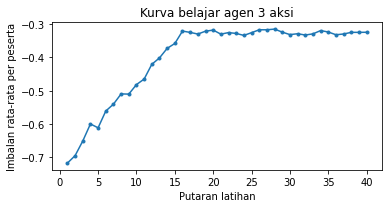

,Butir tambahan sudah dibuka,Pita tebakan,Peluang berat,n,Aksi agen
0,0,Normal,"<0,1",1373,BERHENTI
1,0,Ringan,"<0,1",511,TANYA
2,0,Sedang,"<0,1",692,TANYA
3,0,Sedang,"0,1-0,3",296,TANYA
4,0,Sedang,"0,3-0,5",190,TANYA
5,0,Berat,"0,5-0,7",59,TANYA
6,0,Berat,">=0,7",770,BERHENTI
7,0,Sangat berat,">=0,7",1801,BERHENTI
8,1,Normal,"<0,1",85,TANYA
9,1,Ringan,"<0,1",407,BERHENTI


In [8]:
# =====================================================================
# LANGKAH 4. LATIH DAN PILIH KEBIJAKAN (tanpa menyentuh data uji)
# Tujuan: melatih agen untuk 3 nilai lambda, menilai ketiganya di data latih agen,
# memilih satu dengan aturan yang ditetapkan lebih dulu, lalu menampilkan kurva belajar
# dan tabel keputusan (pedoman triase).
# =====================================================================

# (A) BIAYA TANYA: nilai tetap yang ditetapkan tim sebelum seleksi (TIDAK dicari).
# Yang dicari hanya lambda (biaya ALIHKAN).
BIAYA_TANYA = 0.1
kandidat = []
# (B) COBA TIGA NILAI LAMBDA
for lam in [0.9, 1.0, 1.25]:
    # latih agen 40 putaran dengan lambda ini
    Q, kurva = latih_agen3(lam, BIAYA_TANYA)
    # jalankan tabel Q yang sudah beku pada 5.695 peserta data latih agen
    k_, a_, t_ = jalankan(Q, SA, TA, len(latih_agen))
    # nilai hasilnya; a_ == 2 berarti peserta dialihkan ke konselor
    r = nilai('lambda=%.2f' % lam, yA, t_, a_ == 2, k_, latih_agen)
    # selisih usia (poin persen) = terlewat usia 18-24 dikurangi kelompok usia lain yang terendah
    r['Selisih usia (pp)'] = r['18-24 terlewat (%)'] - min(r['25-34 terlewat (%)'], r['35+ terlewat (%)'])
    # simpan lambda, tabel Q, dan kurva untuk dipakai kemudian
    r['lam'] = lam; r['Q'] = Q; r['kurva'] = kurva; kandidat.append(r)
# tampilkan tabel tiga kandidat (kolom Q dan kurva tidak ditampilkan)
tab_val = pd.DataFrame([{k: v for k, v in r.items() if k not in ('Q', 'kurva')} for r in kandidat])
display(tab_val.round(2))

# (C) ATURAN PEMILIHAN, ditetapkan sebelum melihat hasil:
#   syarat 1: konselor meninjau paling banyak 10% peserta
#   syarat 2: selisih usia paling besar 1 poin persen (bagian "memperhatikan keadilan")
lolos = [r for r in kandidat if r['Ditinjau konselor (%)'] <= 10.0 and r['Selisih usia (pp)'] <= 1.0]
# bila tidak ada kandidat yang lolos, tampilkan peringatan supaya tidak dilaporkan sebagai lolos syarat
if not lolos:
    print('PERINGATAN: tidak ada kandidat yang memenuhi kedua syarat (tinjauan <= 10% dan selisih usia <= 1 pp). '
          'Kebijakan di bawah dipilih dari SEMUA kandidat sehingga syarat dilanggar. Jangan dilaporkan sebagai kebijakan yang memenuhi kendala.')
#   syarat 3: dari yang lolos, pilih yang paling sedikit melewatkan kasus berat
pilih = min(lolos or kandidat, key=lambda r: r['Kasus berat terlewat (%)'])
# kunci tabel Q dan lambda terpilih; inilah kebijakan yang diuji di Langkah 5
Q_PILIH, LAM_PILIH = pilih['Q'], pilih['lam']
print('Kebijakan terpilih: lambda = %.2f, biaya tanya = %.2f' % (LAM_PILIH, BIAYA_TANYA))

# (D) KURVA BELAJAR kebijakan terpilih: nilai rata-rata per peserta di tiap putaran (40 titik).
# Naik di awal (masih banyak mencoba acak), lalu mendatar sekitar putaran 16 (epsilon sudah 5%).
fig, ax = plt.subplots(figsize=(5.5, 3)); ax.plot(range(1, len(pilih['kurva']) + 1), pilih['kurva'], marker='o', ms=3)
ax.set_xlabel('Putaran latihan'); ax.set_ylabel('Imbalan rata-rata per peserta'); ax.set_title('Kurva belajar agen 3 aksi')
plt.tight_layout(); plt.savefig(os.path.join(HASIL, 'kurva_belajar_agen3.png'), dpi=120); plt.show()

# (E) TABEL KEPUTUSAN: kebijakan yang dipelajari, dibaca seperti pedoman triase
# (hanya keadaan yang benar-benar dilewati minimal 20 peserta)
AKSI = ['BERHENTI', 'TANYA', 'ALIHKAN']; KP = ['<0,1', '0,1-0,3', '0,3-0,5', '0,5-0,7', '>=0,7']
kunjungan = np.zeros(NS, int)          # berapa peserta validasi yang benar-benar melewati keadaan ini
# telusuri setiap peserta data latih agen mengikuti kebijakan terpilih, lalu hitung keadaan yang dilewati
for i in range(len(latih_agen)):
    k = 0
    while True:
        s = SA[k][i]; kunjungan[s] += 1
        boleh = [0, 1, 2] if k < KMAX else [0, 2]
        a = boleh[int(np.argmax(Q_PILIH[s, boleh]))]
        if a == 1: k += 1
        else: break
baris_p = []
# susun satu baris untuk tiap keadaan; keadaan yang dilewati kurang dari 20 peserta tidak ditampilkan
for k in range(KMAX + 1):
    for pb in range(5):
        for b in range(5):
            # nomor keadaan dihitung dengan rumus yang sama seperti fungsi keadaan()
            s = k * 25 + pb * 5 + b
            n_s = int(kunjungan[s])
            if n_s < 20: continue
            boleh = [0, 1, 2] if k < KMAX else [0, 2]
            # aksi agen = aksi dengan nilai Q terbesar pada keadaan ini
            baris_p.append({'Butir tambahan sudah dibuka': k, 'Pita tebakan': NAMA_PITA[pb], 'Peluang berat': KP[b], 'n': n_s,
                            'Aksi agen': AKSI[boleh[int(np.argmax(Q_PILIH[s, boleh]))]]})
tab_kebijakan = pd.DataFrame(baris_p)
display(tab_kebijakan)
# simpan tabel keputusan ke folder hasil
tab_kebijakan.to_csv(os.path.join(HASIL, 'kebijakan_agen3.csv'), index=False)

### Cara membaca keluaran Langkah 4

**Tabel tiga kandidat** (keluaran Colab 15 November, kunci 42; pastikan sama setelah *Run all*):

| lambda | Ditinjau konselor | Butir tambahan rata-rata | Kasus berat terlewat | Alarm palsu | Selisih usia | Lolos dua syarat |
|---|---|---|---|---|---|---|
| 0,90 | 7,97% | 0,67 | 5 (0,19%) | 2,63% | 0,21 poin | ya |
| 1,00 | 6,39% | 0,34 | 21 (0,78%) | 2,63% | 0,94 poin | ya |
| 1,25 | 6,30% | 0,33 | 21 (0,78%) | 2,67% | 0,94 poin | ya |

Ketiganya lolos syarat tinjauan paling banyak 10% dan selisih usia paling besar 1 poin persen; lambda 0,90 terpilih karena paling sedikit melewatkan kasus berat. Pemilihan memakai **data latih agen**, bukan data uji.

**Kurva belajar.** Nilai rata-rata naik di awal karena agen masih banyak mencoba acak (epsilon tinggi), lalu mendatar sekitar putaran 16 ketika epsilon sudah 5%.

**Tabel keputusan.** Setiap baris = satu keadaan yang dilewati minimal 20 peserta; kolom terakhir = aksi agen. Polanya: tebakan sudah jelas, BERHENTI; masih ragu, TANYA; ragu yang bertahan setelah bertanya, ALIHKAN. Baris dengan n kecil (misalnya 22 atau 39) dibaca hati-hati.

| Pertanyaan dosen | Jawaban singkat |
|---|---|
| Mengapa biaya tanya 0,1? | Nilai tetap yang ditetapkan tim sebelum seleksi; yang diseleksi hanya lambda. Akibat bila nilainya diubah diperlihatkan di sel demo. |
| Mengapa hanya tiga nilai lambda? | Keterbatasan uji kelayakan; kami menyebutnya "kebijakan terpilih dari tiga kandidat", bukan kebijakan optimal. |
| Di mana unsur keadilannya? | Syarat kedua (selisih usia paling besar 1 poin persen) ikut menentukan kandidat yang boleh dipilih, bukan hanya dilaporkan. |
| Mengapa 40 putaran? | Pilihan tim; kurva sudah mendatar sekitar putaran 16. Jumlah putaran lain belum diuji. |

## Langkah 5. Ujian di data uji dan perbandingan

Kebijakan dikunci, lalu dijalankan pada data uji. Pembanding dijalankan dengan **jumlah tinjauan konselor yang sama** dengan agen:

* **P5 tanpa bertanya**: aturan biaya harapan dari 7 butir (pembanding terkuat di notebook v3).
* **Aturan tetap 3 aksi**: tanya selama peluang berat di antara 0,1 dan 0,7 (maksimal 3 butir), lalu P5.
* **Selalu tanya 3 butir lalu P5**: batas atas bila semua orang ditanya 3 butir tambahan.

Konselor meninjau 480 dari 5695 peserta (8.4%).


,Kebijakan,Ditinjau konselor (%),Butir tambahan rata-rata,Kasus berat terlewat (n),Kasus berat terlewat (%),Alarm palsu (%),Akurasi akhir,18-24 terlewat (%),25-34 terlewat (%),35+ terlewat (%),Laki-laki terlewat (%),Perempuan terlewat (%)
0,P0 tanpa konselor (7 butir),0.00,0.00,183,6.79,2.47,0.82,7.13,5.86,6.33,6.19,7.05
1,P5 tanpa bertanya,8.43,0.00,28,1.04,2.47,0.85,1.27,0.52,0.45,0.88,1.10
2,Aturan tetap 3 aksi,8.43,0.22,24,0.89,3.80,0.86,0.90,1.03,0.45,1.06,0.86
3,Selalu tanya 3 lalu P5,8.43,3.00,6,0.22,2.60,0.90,0.32,0.00,0.00,0.18,0.24
4,Agen RL 3 aksi,8.43,0.68,7,0.26,2.27,0.87,0.37,0.00,0.00,0.18,0.29


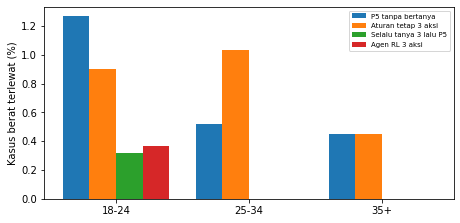

In [9]:
# =====================================================================
# LANGKAH 5. UJIAN DAN PERBANDINGAN
# Tujuan: menjalankan kebijakan terpilih (tabel Q beku) pada 5.695 peserta data uji yang belum
# pernah dipakai, lalu membandingkannya dengan cara lain yang diberi jatah konselor yang sama.
# =====================================================================

# (A) BIAYA HARAPAN: seberapa mahal kesalahan bila tebakan model dipakai apa adanya.
# Dipakai pembanding untuk menentukan siapa yang dialihkan ke konselor (yang paling berisiko lebih dulu).
def biaya_harapan(Pm):
    # pb = pita tebakan; C_ = tabel biaya bila acuan sebenarnya adalah pita k
    pb = Pm.argmax(1); C_ = np.zeros_like(Pm)
    for k in range(Pm.shape[1]):
        # biaya = selisih pita; khusus acuan berat ke atas yang ditebak di bawah berat, biaya = 10
        c = np.abs(k - pb).astype(float); c[(k >= 3) & (pb < 3)] = W_TERLEWAT; C_[:, k] = c
    # biaya harapan = jumlah (peluang pita k x biaya bila pita k yang benar)
    return (Pm * C_).sum(1)

# (B) JALANKAN AGEN PADA DATA UJI
nU = len(uji)
k_u, a_u, t_u = jalankan(Q_PILIH, SU, TU, nU)
# n_tinjau = jumlah peserta yang dialihkan agen; angka ini menjadi JATAH konselor untuk semua pembanding
alih_agen = a_u == 2; n_tinjau = int(alih_agen.sum())

# (C) JATAH SAMA: alihkan n_tinjau peserta dengan biaya harapan tertinggi
def alihkan_teratas(Pm):
    a = np.zeros(nU, bool); a[np.argsort(-biaya_harapan(Pm))[:n_tinjau]] = True; return a

# (D) PEMBANDING ATURAN TETAP 3 AKSI (aturan buatan manusia):
# tanya selama peluang berat di antara 0,1 dan 0,7 (paling banyak 3 butir), lalu berhenti
k_rule = np.zeros(nU, int)
for i in range(nU):
    k = 0
    while k < KMAX and 0.1 <= PU[k][i, 3:].sum() < 0.7: k += 1
    k_rule[i] = k
# peluang akhir tiap peserta setelah mengikuti aturan tetap
P_rule = np.array([PU[k_rule[i]][i] for i in range(nU)])

# (E) LIMA CARA DINILAI PADA DATA UJI YANG SAMA
#   P0            : model 7 butir saja, tanpa konselor (titik awal)
#   P5            : tanpa bertanya; n_tinjau peserta paling berisiko dialihkan
#   Aturan tetap  : bertanya menurut ambang 0,1 sampai 0,7, lalu jatah konselor yang sama
#   Selalu tanya 3: semua peserta menjawab 10 butir, lalu jatah konselor yang sama (batas atas)
#   Agen RL       : kebijakan terpilih dari Langkah 4
baris_u = [nilai('P0 tanpa konselor (7 butir)', yU, TU[0], np.zeros(nU, bool), np.zeros(nU), uji),
           nilai('P5 tanpa bertanya', yU, TU[0], alihkan_teratas(PU[0]), np.zeros(nU), uji),
           nilai('Aturan tetap 3 aksi', yU, P_rule.argmax(1), alihkan_teratas(P_rule), k_rule, uji),
           nilai('Selalu tanya 3 lalu P5', yU, TU[KMAX], alihkan_teratas(PU[KMAX]), np.full(nU, KMAX), uji),
           nilai('Agen RL 3 aksi', yU, t_u, alih_agen, k_u, uji)]
tab_uji = pd.DataFrame(baris_u)
print('Konselor meninjau %d dari %d peserta (%.1f%%).' % (n_tinjau, nU, 100 * n_tinjau / nU))
display(tab_uji.round(2))
# simpan tabel perbandingan ke folder hasil
tab_uji.round(3).to_csv(os.path.join(HASIL, 'perbandingan_agen3.csv'), index=False)

# (F) GRAFIK: kasus berat terlewat per kelompok usia untuk empat cara yang memakai konselor
fig, ax = plt.subplots(figsize=(6.5, 3.2)); x = np.arange(3); w = 0.2
for j, r in enumerate(baris_u[1:]):
    ax.bar(x + (j - 1.5) * w, [r[g + ' terlewat (%)'] for g in ['18-24', '25-34', '35+']], w, label=r['Kebijakan'])
ax.set_xticks(x); ax.set_xticklabels(['18-24', '25-34', '35+']); ax.set_ylabel('Kasus berat terlewat (%)')
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(os.path.join(HASIL, 'kelompok_agen3.png'), dpi=120); plt.show()

### Cara membaca keluaran Langkah 5

Keluaran Colab 15 November, kunci 42 (pastikan sama setelah *Run all*): konselor meninjau **480 dari 5.695 peserta (8,4%)**, dan jatah itu diberikan sama kepada semua pembanding kecuali P0.

| Cara | Butir tambahan rata-rata | Kasus berat terlewat | Alarm palsu |
|---|---|---|---|
| P0 tanpa konselor (7 butir) | 0,00 | 183 | 2,47% |
| P5 tanpa bertanya | 0,00 | 28 | 2,47% |
| Aturan tetap 3 aksi | 0,22 | 24 | 3,80% |
| Selalu tanya 3 lalu P5 | 3,00 | 6 | 2,60% |
| **Agen RL 3 aksi** | **0,68** | **7** | **2,27%** |

Persen kasus terlewat dihitung dari 2.694 peserta uji yang acuannya berat ke atas.

| Pertanyaan  | Jawaban  |
|---|---|
| Mengapa semua pembanding diberi jatah konselor yang sama? | Supaya adil: cara yang mengalihkan lebih banyak orang pasti melewatkan lebih sedikit kasus karena tenaga konselor, bukan karena caranya lebih pintar. |
| Agen kalah dari "selalu tanya 3"? | Ya, 7 lawan 6, tetapi agen hanya bertanya 0,68 butir per orang, bukan 3. Agen adalah kompromi yang lebih hemat. |
| Apakah data uji pernah dipakai saat latihan? | Tidak. Model penebak dilatih pada 17.084 peserta, agen dilatih dan dipilih pada 5.695 peserta lain, dan 5.695 peserta uji baru dipakai di sini. |
| Apakah hasil ini sama untuk pembagian data lain? | Pada enam pembagian (kunci 1 sampai 5 dan 42) rata-rata agen 13 kasus terlewat dengan rentang 7 sampai 19; kunci 42 termasuk hasil terbaik (berkas pemeriksaan terpisah, bukan notebook ini). |

## Demo UTS: bagaimana biaya bertanya mengubah perilaku agen?

Geser **BIAYA_TANYA_DEMO**, lalu jalankan sel (sekitar 10 detik). Bila bertanya dianggap mahal, agen hampir tidak pernah bertanya dan hasilnya mendekati P5. Bila murah, agen bertanya lebih sering pada peserta yang ragu.

In [10]:
# =====================================================================
# DEMO: ubah biaya bertanya, lalu jalankan sel ini
# Hanya agen yang dilatih ulang 40 putaran dengan biaya tanya baru. Data, model penebak,
# lambda terpilih, dan data uji TIDAK berubah. Jadi bila perilaku agen berubah, penyebabnya
# hanya nilai imbalan: itulah ciri reinforcement learning.
# Sel ini tidak menjalankan pemilihan kebijakan (Langkah 4), sehingga tinjauan konselor
# bisa sedikit melewati 10% pada biaya tanya yang besar.
# =====================================================================
# geseran 0 sampai 0,4 dengan langkah 0,05; nilai yang dipakai penelitian adalah 0,1
BIAYA_TANYA_DEMO = 0  #@param {type:"slider", min:0.0, max:0.4, step:0.05}
# latih ulang agen dengan lambda terpilih dan biaya tanya dari geseran
Q_demo, _ = latih_agen3(LAM_PILIH, BIAYA_TANYA_DEMO)
# jalankan tabel Q baru pada data uji yang sama seperti Langkah 5
k_d, a_d, t_d = jalankan(Q_demo, SU, TU, nU)
# nilai hasilnya dengan fungsi yang sama seperti Langkah 5
r = nilai('Agen RL 3 aksi, biaya tanya %.2f' % BIAYA_TANYA_DEMO, yU, t_d, a_d == 2, k_d, uji)
# cetak ringkasan; bandingkan dengan baris "Agen RL 3 aksi" pada tabel Langkah 5
print('Rata-rata butir tambahan: %.2f | ditinjau konselor: %.1f%% | kasus berat terlewat: %d (%.2f%%) | alarm palsu: %.2f%%'
      % (r['Butir tambahan rata-rata'], r['Ditinjau konselor (%)'], r['Kasus berat terlewat (n)'], r['Kasus berat terlewat (%)'], r['Alarm palsu (%)']))
print('Terlewat per usia: 18-24 %.2f%% | 25-34 %.2f%% | 35+ %.2f%%' % (r['18-24 terlewat (%)'], r['25-34 terlewat (%)'], r['35+ terlewat (%)']))
print('Terlewat per gender: laki-laki %.2f%% | perempuan %.2f%%' % (r['Laki-laki terlewat (%)'], r['Perempuan terlewat (%)']))

Rata-rata butir tambahan: 2.76 | ditinjau konselor: 8.6% | kasus berat terlewat: 9 (0.33%) | alarm palsu: 0.90%
Terlewat per usia: 18-24 0.42% | 25-34 0.17% | 35+ 0.00%
Terlewat per gender: laki-laki 0.35% | perempuan 0.33%


### Cara membaca keluaran demo

Hasil seluruh posisi geseran (berkas pemeriksaan, Colab, kunci 42, lambda 0,90):

| Biaya tanya | Butir tambahan rata-rata | Ditinjau konselor | Kasus berat terlewat | Alarm palsu |
|---|---|---|---|---|
| 0,00 | 2,76 | 8,6% | 9 | 0,90% |
| 0,05 | 1,15 | 8,9% | 9 | 0,80% |
| 0,10 (setelan penelitian) | 0,68 | 8,4% | 7 | 2,27% |
| 0,15 | 0,01 | 9,9% | 19 | 2,13% |
| 0,20 sampai 0,40 | 0,00 | 10,3% | 19 | 2,07% |

**Urutan demo (sekitar 60 detik).** Tunjukkan dulu hasil Langkah 5 (480 tinjauan, 7 terlewat). Geser ke 0 dan jalankan: bertanya gratis, agen bertanya hampir kepada semua orang. Geser ke 0,30 dan jalankan: bertanya mahal, agen berhenti bertanya, kasus terlewat naik menjadi 19.

| Pertanyaan dosen | Jawaban singkat |
|---|---|
| Apa buktinya bagian ini RL? | Yang diubah hanya nilai imbalan; data dan model penebak tetap; kebiasaan agen berubah. Agen belajar dari imbalan, bukan dari jawaban benar. |
| Apa dasar langkah geseran 0,05? | Pilihan tampilan demo: cukup halus untuk melihat perubahan perilaku, dan nilai penelitian 0,1 ada di dalamnya. |
| Mengapa biaya 0 tidak paling baik? | Bertanya lebih murah tidak otomatis lebih baik: pada biaya 0 dan 0,05 ada 9 kasus terlewat, pada 0,10 ada 7. |
| Mengapa tinjauan bisa 10,3%? | Sel demo tidak menjalankan pemilihan kebijakan, jadi syarat 10% tidak diperiksa ulang. |

## Cara membaca hasil dan batasannya

1. **Yang diuji adalah keputusan langkah berikutnya**, bukan kemampuan menebak pita. Tebakan tetap dibuat model penebak.
2. **Pembanding dibuat adil**: semua kebijakan memakai jumlah tinjauan konselor yang sama dengan agen. Agen yang terlihat unggul karena mengalihkan lebih banyak orang bukan temuan.
3. **Biaya bertanya adalah pilihan nilai.** Hasil harus dilaporkan untuk beberapa nilai biaya (analisis sensitivitas), bukan hanya nilai terbaik.
4. **Acuan bukan diagnosis.** "Berat" berarti kategori skor 14 butir DASS-42, bukan hasil wawancara klinis. Karena acuan dihitung dari 14 butir, membuka butir tambahan otomatis mendekatkan tebakan ke acuan. Ini harus ditulis terang di makalah.
5. **Data latih agen dan data pemilihan kebijakan masih sama** (data validasi). Versi final membaginya menjadi dua bagian.
6. **Satu seed tidak cukup.** Pengecekan awal dengan enam pembagian data (seed 1 sampai 5 dan 42) memberi pola yang sama: agen melewatkan lebih sedikit kasus berat dibanding P5 dan aturan tetap pada jumlah tinjauan yang sama, tetapi angkanya bervariasi (7 sampai 19 kasus, rata-rata 13). Seed 42 termasuk hasil terbaik (7 kasus, sama dengan seed 5), jadi laporkan rata-rata dan rentang, bukan satu angka.
7. **Kapasitas konselor belum terpakai penuh** (5,1 sampai 8,8 persen pada enam pembagian data, padahal batasnya 10 persen) karena pilihan λ masih kasar. Uji sensitivitas batas tinjauan (10,0 dibanding 10,5) pada tujuh pembagian data (seed 1 sampai 6 dan 42) memberi kebijakan terpilih yang sama, sebab tinjauan terbesar di antara kandidat validasi hanya 9,4 persen; yang benar-benar menyaring kandidat adalah syarat selisih usia 1 poin persen (dua dari 21 kandidat, yaitu λ 1,00 dan 1,25 pada seed 3, dengan selisih 1,37 poin), dan pilihan akhir tetap sama karena kedua kandidat itu juga melewatkan lebih banyak kasus berat. Versi final memakai lebih banyak nilai λ.
8. **Konselor dianggap selalu benar.** Dalam simulasi, kasus yang dialihkan langsung memperoleh kategori acuan. Konselor nyata bisa keliru dan bisa menolak beban tambahan.
9. Data berasal dari responden daring sukarela internasional, bukan mahasiswa Indonesia. Hasil adalah uji metode dalam simulasi, belum dasar penerapan pada mahasiswa nyata.

